In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

In [6]:
data = load_breast_cancer()
X = pd.DataFrame(data.data,columns=data.feature_names)
y = pd.Series(data.target, name = 'Cancer') 

In [7]:
X.head()

,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


In [8]:
X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.3,random_state=42)

## Logistic regression: 5 fold cross validation

In [9]:
cv_scores = cross_val_score(LogisticRegression(max_iter = 10000, solver = 'liblinear'), X, y, cv=5, scoring = 'accuracy')

print('Fold-wise Accuracy Scores:', cv_scores)
print("Average Accuracy: ", np.mean(cv_scores))

Fold-wise Accuracy Scores: [0.92982456 0.93859649 0.97368421 0.94736842 0.96460177]
Average Accuracy:  0.9508150908244062


In [11]:
dt = DecisionTreeClassifier(random_state=42)
cv_scores_dt = cross_val_score(dt, X, y, cv = 5, scoring='accuracy')

print('Fold-wise Accuracy Scores(Dt):', cv_scores_dt)
print("Average Accuracy (Dt): ", np.mean(cv_scores_dt))

Fold-wise Accuracy Scores(Dt): [0.9122807  0.90350877 0.92982456 0.95614035 0.88495575]
Average Accuracy (Dt):  0.9173420276354604


# Cross validation and Gridsearch

**we used this technique to check accuracy of a model for different combinations of parameters.  then apply to total dat**

In [14]:
param_grid_dt = {
    'max_depth' : [3,5,10,None],
    'min_samples_split' : [2,5,10],
    'criterion' : ['gini','entropy']
}

grid_dt = GridSearchCV(DecisionTreeClassifier(random_state=42),param_grid=param_grid_dt, cv=5, scoring='accuracy',n_jobs=1)
grid_dt.fit(X_train,y_train)

print("Best parametrs (DT): ", grid_dt.best_params_)
print("Best accuracy (DT): ", grid_dt.best_score_)

Best parametrs (DT):  {'criterion': 'entropy', 'max_depth': 3, 'min_samples_split': 2}
Best accuracy (DT):  0.9397468354430378


In [16]:
best_dt = grid_dt.best_estimator_

y_pred_dt  = best_dt.predict(X_test)

print("\nBest Decision tree test Accuracy: ", accuracy_score(y_test,y_pred_dt))
print(confusion_matrix(y_test, y_pred_dt))


Best Decision tree test Accuracy:  0.9707602339181286
[[ 59   4]
 [  1 107]]


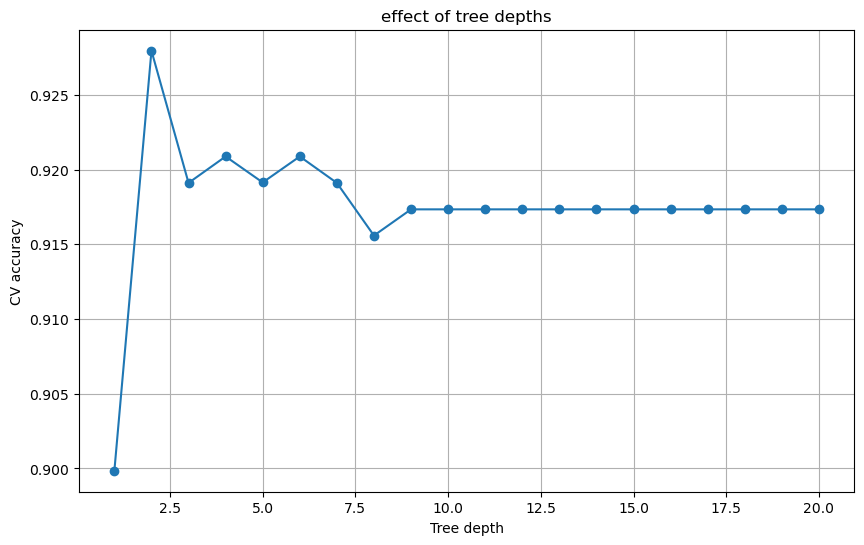

In [20]:
depths = range(1,21)
accuracy_score = []

for d in depths:
    tree = DecisionTreeClassifier(max_depth=d,random_state=42)
    scores = cross_val_score(tree, X, y, cv = 5, scoring='accuracy')
    accuracy_score.append(np.mean(scores))
    
plt.figure(figsize=(10,6))
plt.plot(depths,accuracy_score,marker='o')
plt.xlabel("Tree depth")
plt.ylabel("CV accuracy")
plt.title("effect of tree depths")
plt.grid(True)
plt.show()